### Uczenie nadzorowane - predykcja

Łukasz Całka <br>
Uczenie Maszynowe

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm

1. Wczytanie danych:


In [2]:
columns = [
    "CRIM",     # wskaźnik przestępczości na mieszkańca
    "ZN",       # odsetek gruntów pod duże działki mieszkalne (>25 000 stóp kw.)
    "INDUS",    # odsetek powierzchni przemysłowej / biznesowej
    "CHAS",     # sąsiedztwo rzeki Charles (1 = tak, 0 = nie)
    "NOX",      # stężenie tlenków azotu w powietrzu
    "RM",       # średnia liczba pokoi w mieszkaniu
    "AGE",      # odsetek domów zbudowanych przed 1940 r.
    "DIS",      # ważona odległość do 5 centrów zatrudnienia
    "RAD",      # indeks dostępności do głównych dróg / autostrad
    "TAX",      # stawka podatku od nieruchomości (na 10 000 USD)
    "PTRATIO",  # stosunek liczby uczniów do nauczycieli
    "B",        # wskaźnik demograficzny 1000(Bk - 0.63)^2
    "LSTAT",    # odsetek ludności o niższym statusie społeczno-ekonomicznym
    "MEDV"      # mediana cen domów w tys. USD (zmienna celu)
]

df = pd.read_csv(
    "housing.data.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

print(df.shape)
print(df.head())

(506, 14)
      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD    TAX  \
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296.0   
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242.0   
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242.0   
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222.0   
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222.0   

   PTRATIO       B  LSTAT  MEDV  
0     15.3  396.90   4.98  24.0  
1     17.8  396.90   9.14  21.6  
2     17.8  392.83   4.03  34.7  
3     18.7  394.63   2.94  33.4  
4     18.7  396.90   5.33  36.2  


2. EDA

In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CRIM,506.0,3.613524,8.601545,0.00632,0.082045,0.25651,3.677083,88.9762
ZN,506.0,11.363636,23.322453,0.00000,0.000000,0.00000,12.500000,100.0000
INDUS,506.0,11.136779,6.860353,0.46000,5.190000,9.69000,18.100000,27.7400
CHAS,506.0,0.069170,0.253994,0.00000,0.000000,0.00000,0.000000,1.0000
NOX,506.0,0.554695,0.115878,0.38500,0.449000,0.53800,0.624000,0.8710
RM,506.0,6.284634,0.702617,3.56100,5.885500,6.20850,6.623500,8.7800
AGE,506.0,68.574901,28.148861,2.90000,45.025000,77.50000,94.075000,100.0000
DIS,506.0,3.795043,2.105710,1.12960,2.100175,3.20745,5.188425,12.1265
RAD,506.0,9.549407,8.707259,1.00000,4.000000,5.00000,24.000000,24.0000
TAX,506.0,408.237154,168.537116,187.00000,279.000000,330.00000,666.000000,711.0000


array([[<Axes: title={'center': 'CRIM'}>, <Axes: title={'center': 'ZN'}>,
        <Axes: title={'center': 'INDUS'}>,
        <Axes: title={'center': 'CHAS'}>],
       [<Axes: title={'center': 'NOX'}>, <Axes: title={'center': 'RM'}>,
        <Axes: title={'center': 'AGE'}>, <Axes: title={'center': 'DIS'}>],
       [<Axes: title={'center': 'RAD'}>, <Axes: title={'center': 'TAX'}>,
        <Axes: title={'center': 'PTRATIO'}>,
        <Axes: title={'center': 'B'}>],
       [<Axes: title={'center': 'LSTAT'}>,
        <Axes: title={'center': 'MEDV'}>, <Axes: >, <Axes: >]],
      dtype=object)

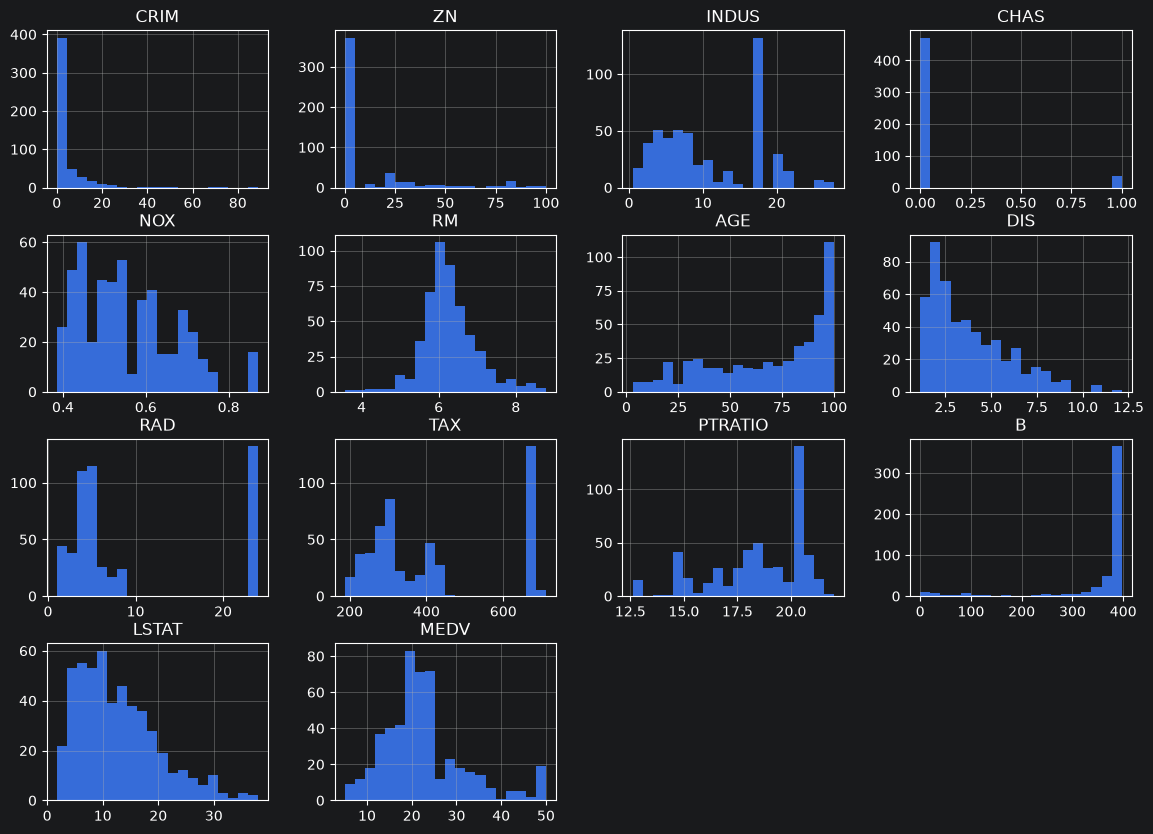

In [5]:
df.hist(figsize=(14, 10), bins=20)

In [6]:
df.corr()["MEDV"].sort_values()

LSTAT     -0.737663
PTRATIO   -0.507787
INDUS     -0.483725
TAX       -0.468536
NOX       -0.427321
CRIM      -0.388305
RAD       -0.381626
AGE       -0.376955
CHAS       0.175260
DIS        0.249929
B          0.333461
ZN         0.360445
RM         0.695360
MEDV       1.000000
Name: MEDV, dtype: float64

<Axes: xlabel='LSTAT', ylabel='MEDV'>

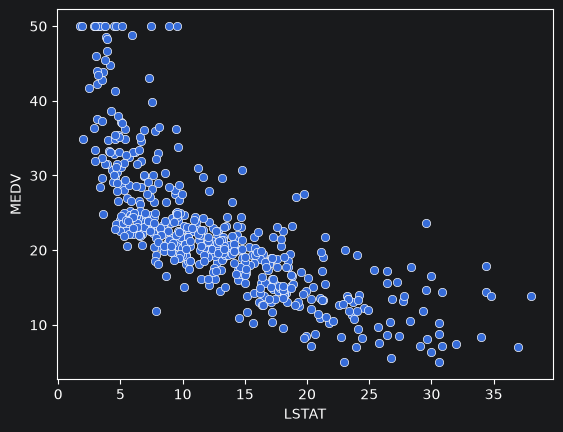

In [7]:
sns.scatterplot(df, x = "LSTAT", y = "MEDV" )

<Axes: xlabel='RM', ylabel='MEDV'>

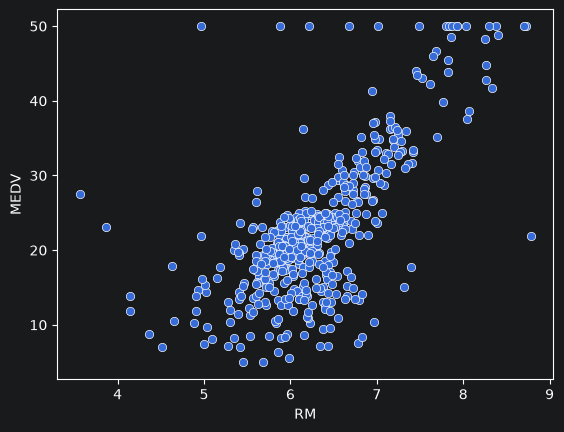

In [8]:
sns.scatterplot(df, x = "RM", y = "MEDV" )

<Axes: xlabel='PTRATIO', ylabel='MEDV'>

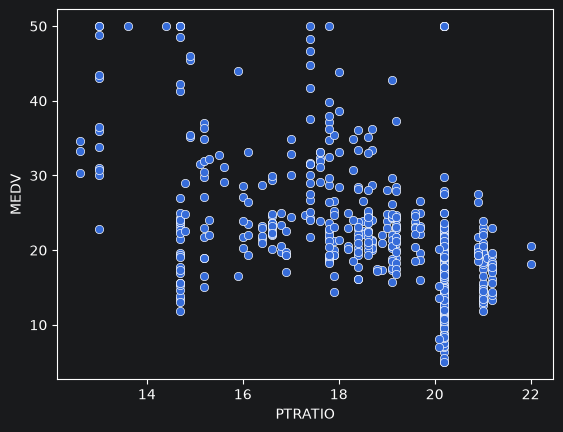

In [9]:
sns.scatterplot(df, x = "PTRATIO", y = "MEDV" )

<Axes: >

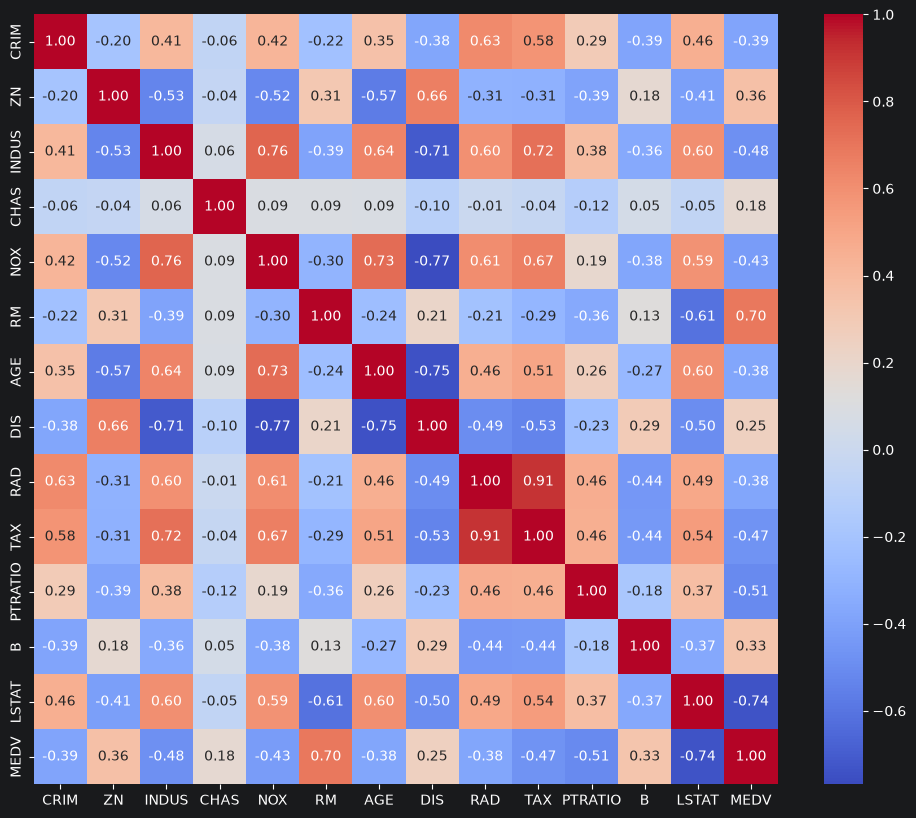

In [10]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")

Wnioski z EDA: <br>
Zauważono, iż niektóre z najsilniej korelujących z MEDV zmiennych nie są w korelacji liniowej. Chociażby w przypadku zmiennej LSTAT wykres punktowy układa się w łuk, co przeczy czystej korelacji liniowej. Zaobserwowano także na macierzy korelacji, że niektóre zmienne silnie korelują ze sobą (np. TAX i RAD — 0.91), co oznacza, że są one prawdopodobnie współliniowe.

3. Podział danych

In [11]:
from sklearn.model_selection import train_test_split

X = df.drop("MEDV", axis=1)
Y = df['MEDV']
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42)

4. Badanie modeli

In [12]:
from sklearn.linear_model import LinearRegression
model_lr = LinearRegression()
model_lr.fit(X_train, Y_train)

import xgboost as xgb

xg_reg = xgb.XGBRegressor(
    objective="reg:squarederror",  # funkcja straty: błąd średniokwadratowy (MSE)
    colsample_bytree=0.3,          # odsetek cech losowanych przy budowie każdego drzewa (30%)
    learning_rate=0.1,             # współczynnik uczenia (waga wkładu każdego nowego drzewa)
    max_depth=5,                   # maksymalna głębokość pojedynczego drzewa
    alpha=10,                      # regularyzacja L1 na wagach w liściach (kara za złożoność)
    n_estimators=100               # liczba drzew budowanych sekwencyjnie
)

xg_reg.fit(X_train, Y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.3
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


5. Optymalne parametry XGBoost

In [13]:
from sklearn.model_selection import GridSearchCV

params = {
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'n_estimators': [50, 100, 150, 200],
    'max_depth': [3, 5, 7],
    'colsample_bytree': [0.3, 0.8, 1.0],
    'reg_alpha': [0, 1, 10]
}

xg_reg = xgb.XGBRegressor(objective="reg:squarederror")

grid = GridSearchCV(
    estimator=xg_reg,                   # model bazowy, dla którego szukamy najlepszych parametrów
    param_grid=params,                  # słownik z siatką hiperparametrów do przetestowania
    cv=5,                               # 5-krotna walidacja krzyżowa (cross-validation)
    scoring="neg_mean_squared_error",   # metryka oceny: ujemny MSE (im bliżej 0, tym lepiej)
    n_jobs=-1                           # użycie wszystkich dostępnych rdzeni CPU do obliczeń równoległych
)

grid.fit(X_train, Y_train)

print("Best score: %f using params: %s" % (grid.best_score_, grid.best_params_))

Best score: -12.315178 using params: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200, 'reg_alpha': 1}


Porównanie modeli

In [14]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Predykcje na zbiorze testowym
y_pred_lr = model_lr.predict(X_test)
y_pred_xgb = grid.best_estimator_.predict(X_test)

mse_lr = mean_squared_error(Y_test, y_pred_lr)
mse_xgb = mean_squared_error(Y_test, y_pred_xgb)

wyniki = pd.DataFrame({
    "Model": ["Linear Regression", "XGBoost"],
    "MSE": [mse_lr, mse_xgb],
    "RMSE": [np.sqrt(mse_lr), np.sqrt(mse_xgb)],
    "MAE": [mean_absolute_error(Y_test, y_pred_lr), mean_absolute_error(Y_test, y_pred_xgb)],
    "R2": [r2_score(Y_test, y_pred_lr), r2_score(Y_test, y_pred_xgb)],
}).set_index("Model").round(4)

wyniki

,MSE,RMSE,MAE,R2
Model,,,,
Linear Regression,24.2911,4.9286,3.1891,0.6688
XGBoost,6.8848,2.6239,1.9181,0.9061


Na zbiorze testowym zdecydowanie lepiej spisał się model XGBoost, osiągając ponad 3-krotnie niższy błąd MSE (6,88 vs 24.29), wyraźnie niższy RMSE (2.62 vs 4.93) oraz niemal połowę niższy błąd MAE (1.92 vs 3.19 tys. USD) niż regresja liniowa. Model XGBoost wyjaśnia aż 90,6% wariancji cen nieruchomości ($R^2 = 0{,}91$), podczas gdy regresja liniowa jedynie 66,9% ($R^2 = 0{,}67$), co wyraźnie potwierdza przewagę modeli nieliniowych na tym zbiorze.





6. Sprawdzanie założeń regresji liniowej

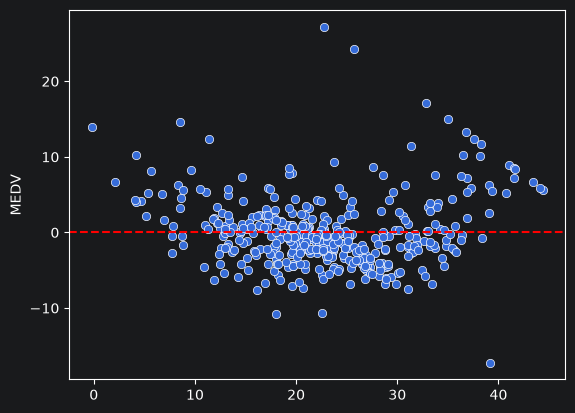

In [15]:
y_pred_train = model_lr.predict(X_train)  #sprawdzamy na danych uczących

residuals = Y_train - y_pred_train

sns.scatterplot(x=y_pred_train, y=residuals)
plt.axhline(0, color='red', linestyle='--')
plt.show()

Zależność nie do końca liniowa. Obserwowano to wcześniej na wykresach scatterplot dla poszczególnych zmiennych, a teraz dla rezyduów - układają się w kształt U

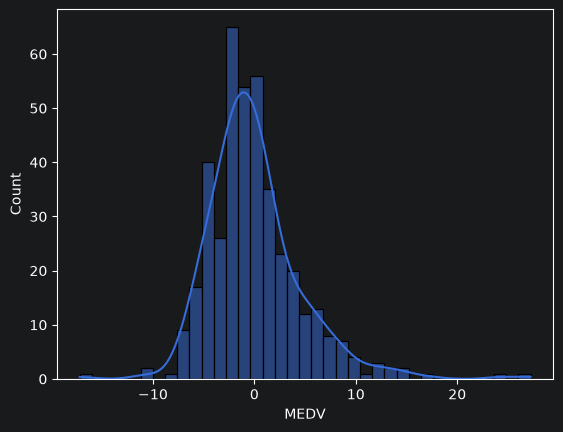

In [16]:
sns.histplot(residuals, kde=True)
plt.show()

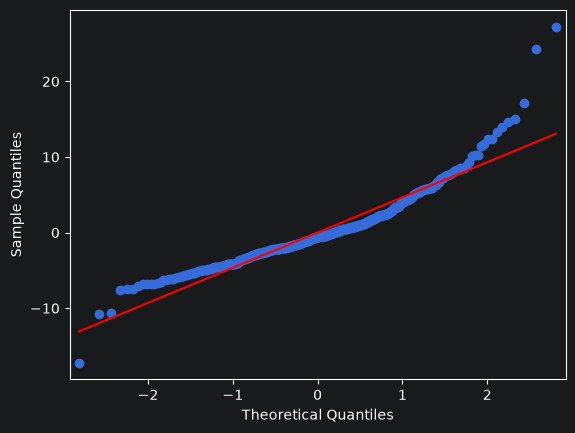

In [17]:
from statsmodels.graphics.gofplots import qqplot

qqplot(residuals, line="s")
plt.show()

Niespełniona także normalność reszt, ich rozkład jest skośny

In [18]:
print(sm.stats.stattools.durbin_watson(residuals)) #między 1.5-2.5

2.114122873215523


brak autokorelacji reszt

Złamana jest także niewspółliniowość zmiennych, istnieją silne korelacje między poszczególnymi zmiennymi.

Złamana jest, więc większość założeń regresji liniowej


W zadaniu wykorzystano narzedzia generatywnej sztucznej inteligencji do przeprowadzenia reaserchu na temat zbioru danych a także do wygenerowania opisów wykorzystywanych funkcji.